## Computational Maths Inter-Collegic Class 4

### TA: Thomas Higham


This week has a proper introduction to numpy

-   np.array([])
-   np.arange(start, end, step)
-   np.linspace(start, end, number of points)
-   np.zeros()
-   np.ones()  


A key difference between lists, [], and numpy arrays, np.array([]), is that lists can store mixes of any data types. Numpy arrays require all entries to be the same type.

This means every entry of a numpy array occupies the same amount of memory (bits).
We can check this:

In [4]:
import numpy as np
from pympler import asizeof #This is not a package you are expected to use

list = [0, 1.0, 77.00]
array = np.array([0, 1, 77])

print("The memory used by the list is", asizeof.asizeof(list))
print("The memory used by the array is", asizeof.asizeof(array))

# Note normally should use array.nbytes but this doesn't work on lists! Only np arrays.

The memory used by the list is 168
The memory used by the array is 152


Another key idea with numpy is the implementation of efficient vector-values functions. Say if you want to take the sine of a vector. This is faster than looping and applying the scalar-valued sine to each component as the np.sin function is pre-compiled and avoids Python's overhead and saftey checks.

Lets check this

In [5]:
import time
import math

def sinefunc(v):
    """
    A function that applies sine component-wise in a vector
    Input: v - numpy array
    Output: w - numpy array of same length
    """

    n = len(v)
    w = np.zeros(n)

    for i in range(n):
        w[i] = math.sin(v[i]) # the math.sin function cannot be applied to a vector.

    return w    

vec = np.arange(1,100000)

# Timing the for loop approach
start1 = time.perf_counter()
sinvec = sinefunc(vec)
end1 = time.perf_counter()
time1 = end1 - start1

# Timing the pre-compiled np.sin approach
start2 = time.perf_counter()
sinvec = np.sin(vec)
end2 = time.perf_counter()
time2 = end2 - start2

print(f"The for loop approach took {time1:.6f} seconds")
print(f"The np.sin approach took {time2:.6f} seconds")

The for loop approach took 0.018523 seconds
The np.sin approach took 0.000660 seconds


### Exercise 12.1
Let $x$ and $y$ be two numpy arrays representing the $x$
and $y$- coordinates of a discretely sampled function in one dimension.
Say that $x_i$ is near a root if the sign of $y_i$ is different to the sign of $y_{i+1}$.

Write one line of Python to identify the entries of $x$ that are near a root.

In [6]:
x = np.array([1,2,3,4])
y = np.array([-1,1,2,-1])

"""
First we do a longer naive approach.
"""

y_boolean = y>=0 # Assigns each entry a Boolean value
x_near = [] # list makes appending easier

for i in range(len(y)-1):
    if y_boolean[i] != y_boolean[i+1]:
        x_near.append(x[i])
 
print("The entries of x near a root for first approach are", np.array(x_near))
"""
Now we do in one line
"""
x_near = x[:-1][ np.sign(y[:-1]) != np.sign(y[1:])]
# [:-1] means up to but not including last entry
# shifted arrays


print("The entries of x near a root for second approach are", x_near)

The entries of x near a root for first approach are [1 3]
The entries of x near a root for second approach are [1 3]


Now we look at matrices
- np.array([ [row 1], [row 2], [row3] ])
- np.eye(n)
- use @ for matrix-vector or matrix-matrix multiplication or vector-vector dot product.




### Exercise 12.2
The Pauli matrices
$$ \sigma_x  = \begin{pmatrix}0 & 1 \\ 1 & 0 \end{pmatrix}, \quad \sigma_y = \begin{pmatrix} 0 & -i \\ i & 0 \end{pmatrix}, \quad \sigma_z = \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix} $$
form a basis for the Hermitian $2 \times 2$ matrices, and hence for complex observable quantities in quantum mechanics. They oocur in the Pauli equation which accounts for the interaction of the spin o a particle with an external electromagnetic field.
Verify that each Pauli matrix is Hermitian $(\sigma = \sigma^*)$, unitary $(\sigma^{-1} = \sigma^*)$, and hence involutary $(\sigma = \sigma^-1)$.  

In [7]:
# I only do this for sigma y

sigy = np.array([ [0, -1j], [1j, 0] ])
sigy_H = sigy.conj().T # Notes uses depreciated sigy.H 
sigy_inv = np.linalg.inv(sigy)

# Python finds sigy == sigy_H ambiguous as it's unclear whether term by term of wholistic equality

if np.allclose(sigy, sigy_H):
    print("sigma_y is Hermitian")

if np.allclose(sigy_inv, sigy_H):
    print("sigma_y is unitary")
    

sigma_y is Hermitian
sigma_y is unitary


### Numerical Linear Algebra

We now solve 
$$A x = b$$
using the package Scipy.

In [8]:
import scipy as sc
A = np.array([[3, 4, 1], [-1, 8, 6], [5, 6, 7]])
b = np.arange(3)
x = sc.linalg.solve(A, b)
print("x is", x)

x is [ 0.0617284  -0.13580247  0.35802469]


Computational complexity for different NLA methods

- Matrix-vector multiply
- Matrix-matrix multiply
- computing a determinant 
- inverting a matrix naively $(A^{-1} = \frac{1}{\mathrm{det}A} \mathrm{adj}(A) )$ 
- inverting a matrix using LU decomposition




- $O(n^2)$
- $O(n^3)$
- $O(n!)$
- $O(n!)$
- $O(n^3)$

All of these assume matrices are dense. If we have a sparse matrix we can run methods much faster by exploiting structure.

### Exercise 12.3
The matrix
$$ F = \begin{pmatrix} 1 & 1 \\ 1 & 0 \end{pmatrix}$$
can be used to produce the Fibonacci sequence by repeated multiplication. The top-left element of $F^n$ is the $(n+1)^{\text{th}}$ Fibonacci number. 
Use the eigenvalue decomposition of $F$ to efficiently calculate the $1100^{\text{th}}$ Fibonacci number.

In [9]:
F = np.array([[1,1],[1,0]])
eigvalF, eigvecF = sc.linalg.eig(F)
Sigma = np.array([[eigvalF[0],0],[0,eigvalF[1]]])
print(f"The matrix of eigenvalues is \n {Sigma}")

def Fibonacci(n):
    """
    Computes the nth Fibonacci number using matrix decomposition
    """
    
    SigmaN = np.linalg.matrix_power(Sigma, n)
    Fib = eigvecF @ SigmaN @ eigvecF.T
    return int(np.rint(Fib[0, 0].real)) # This rounds the Fib number, converts to real, then casts as integer

print(f"The 1100th Fibonacci number is {Fibonacci(1100):.3e}")

The matrix of eigenvalues is 
 [[ 1.61803399+0.j  0.        +0.j]
 [ 0.        +0.j -0.61803399+0.j]]
The 1100th Fibonacci number is 5.571e+229


- $A$ matrix is diagonalisable if and only if it has a full set of linearly independent eigenvectors.
- If $A$ has n distinct eigenvalues it is diagonalisable but this implication is one direction only. (for example the $\mathbf{0}$ matrix)
- $A$ is a normal matrix ($A^TA =AA^T$) iff it is unitarily (orthogonally) diagonalisable.
This holds for a symmetric matrix!


### Introducing the lamda function

Sometimes we need to input a function into another but we don't care to store it otherwise.

__lambda__ is a statement that defines an anonymous function (without a name). For example using QUADPACK (quadrature rule implemented within Scipy),

In [14]:
# Example lambda function
square = lambda x: x*x

# Quadrature rule example
print("first example:", sc.integrate.quad(lambda x: np.sqrt(1-x**4), 0, 1) )

# Dealing with singularities
print("Second example", sc.integrate.quad(lambda x: np.sin(1/x)/x, -np.pi, np.pi, points=[0]) )

first example: (0.8740191847640388, 3.7333125479932505e-10)
Second example (4.177025893645531, 2.9545878037399884)


/var/folders/_4/pkl_j_hs0gzb_rkhzmn1km340000gn/T/ipykernel_13119/445401091.py:8: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  print("Second example", sc.integrate.quad(lambda x: np.sin(1/x)/x, -np.pi, np.pi, points=[0]) )


Ex 12.4 shows a quadrature example

### Least squares and curve fitting

Given data $\{ x_i \}_{i=1}^n , \{ y_i \}_{i=1}^n $, we want to find the polynomial $p(x)$ in the vector space $\Pi_k$ of polynomials of degree $k$ such that
$$ p = \mathrm{arg min}_{q \in \Pi_k} \sum_{i = 1}^n | q(x_i) - y_i |^2 .$$

### Exercise 12.5 
The number of particles $N(t)$ of an isotope undergoing radioactive decay satisfies
$$ N(t) = N_0 \exp(- t / \tau),$$
where $N_0$ is the initial number of particles and $\tau$ is related to the half-life $t_{1/2}$ via $t_{1/2} = \tau \log 2$. Taking logarithms we find
$$ \log N = \log N_0 - \frac{t}{\tau}.$$
If we fit a linear polynomial between $t$ and $\log N$, the slope estimates the reciprocal of $\tau$ and hence $t_{1/2}$.
Using given data estimate the half-life of the given isotope of Berkelium. 

In [11]:
import numpy as np
# Recorded data: times in seconds
t = np.array([ 0., 1., 2., 3., 4., 5., 6., 7., 8., 9.,10.,11.,12.,13.,14.,
15.,16.,17.,18.,19.,20.,21.,22.,23.,24.,25.,26.,27.,28.,29.,30.,31.,
32.,33.,34.,35.,36.,37.,38.,39.,40.,41.,42.,43.,44.,45.,46.,47.,48.,
49.,50.])
# Recorded data: number of particles
N = np.array([100000, 96597, 93400, 90396, 87325, 84345, 81515, 78746,
76133, 73610, 71221, 68934, 66718, 64502, 62332, 60264, 58326,
56448, 54618, 52860, 51142, 49498, 47902, 46277, 44690, 43224,
41735, 40309, 38980, 37615, 36441, 35294, 34046, 33039, 31926,
30891, 29866, 28907, 27956, 27039, 26173, 25344, 24486, 23685,
22898, 22100, 21364, 20649, 19992, 19368, 18722])
logN = np.log(N)
# (dependent variable, independent variable, linear degree)
fit = np.polynomial.Polynomial.fit(t, logN, deg=1).convert()
(c, m) = fit.coef
print(f"The polynomial is y = {m}x + {c}")
tau = -1/m
t_half = tau * np.log(2)
print(f"Estimated half life of Berkelium-233: {t_half:.3f}")

The polynomial is y = -0.033472385557374355x + 11.510083893238317
Estimated half life of Berkelium-233: 20.708


Here we have (input, output) pairs and we fit the nearest polynomial of degree of our choice.

Sometimes we choose to fit to another function and have some initial guess of the parameters of said function - for this we need sc.optimize.curve_fit.

Think about fitting a normal distribution $\mathcal{N}(\mu, \sigma^2)$ to data using parameters $\mu, \sigma$.

There's a good example on page $131$ of notes.

### Solving differential equation IVPs with scipy

In the previous section of the notes we used Sympy to solve ODE IVPs. This works when there is a closed solution in terms of elementary functions. Often the systems are too complicated and we need to numerically solve the equations.

Suppose we have a system of ODEs subject to initial conditions
$$ \dot{\mathbf{y}} = \mathbf{f}(t, \mathbf{y}), $$
$$ \mathbf{y}(t_0) = \mathbf{y}_0.$$

Scipy can solve this using sc.integrate.solve_ivp

Three arguments 
- a function f(t, y) representing the system
- a tuple containing the initial and final times of the simulation
- the data for initial conditions.



### Pendulum problem
Lets solve
$$ \frac{d^2 \theta}{d t^2} = - \frac{g}{l} \sin \theta, \quad \theta(0) = \theta_0, \; \dot{\theta}(0) = 0. $$

Note had we assumed the small angle approximation holds we can get an analytical solution
$\theta(t) = \theta_0 \cos \left( \sqrt{\frac{g}{l}} \right) $. We see how this holds up when ${\theta}_0 = 5 \pi /6 $.

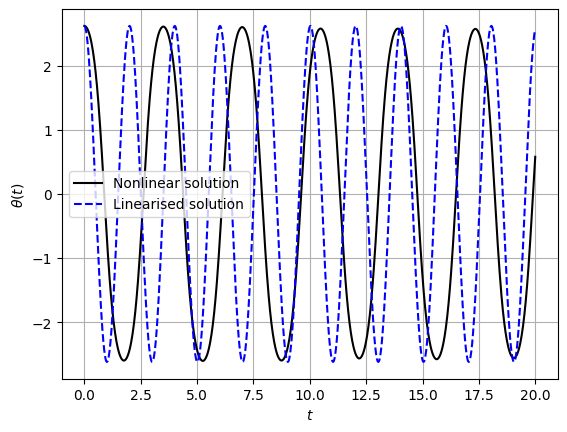

In [16]:
import numpy as np
import scipy as sc
import matplotlib.pyplot as plt

g = 9.81 # acceleration due to gravity
l = 1 # length of the pendulum
ic = [5*np.pi/6, 0] # initial conditions
interval = (0, 20) # interval of interest

def f(t, theta):
    """
    theta is a private variable here
    t isn't used!
    """
    return [theta[1], -g/l * np.sin(theta[0])]

soln = sc.integrate.solve_ivp(f, (0, 20), ic, dense_output=True)

# Get time grid for plotting
t = np.linspace(*interval, 1001)
# Evaluate numerical solution, and analytical solution of linearised problem
ntheta = soln.sol(t)[0]
atheta = ic[0] * np.cos(np.sqrt(g/l) * t)

plt.grid()
plt.plot(t, ntheta, color='k', label="Nonlinear solution")
plt.plot(t, atheta, color='b', linestyle = '--', label="Linearised solution")
plt.xlabel(r"$t$")
plt.ylabel(r"$\theta(t)$")
plt.legend()
plt.show( )

Something cool we can do is set an "event" we want to track. The events attribute tracks when a given function is $0$, for example $\theta = 0$.

In [17]:
def h(t, theta):
    return theta[0]
soln = sc.integrate.solve_ivp(f, (0, 20), ic, events= h)
print("Times at which the pendulum is vertical: ")
print(soln.t_events[0]) # Events of the first functional, i.e. h

Times at which the pendulum is vertical: 
[ 0.88400057  2.62663338  4.38157861  6.13021102  7.87650268  9.61774862
 11.33902179 13.04707701 14.76791401 16.48767437 18.20265162 19.90232232]


The chapter 13 - coda, will help with question 2 of worksheet 4 (with importing NASA databse).